# Week 8: using the differentiable emulator

The emulator is the Week 7 one in [`emulator.py`](../emulator.py), unchanged: pattern scaling driven by a lagged linear
model of global-mean warming. See `Week7_Emulator.ipynb` for its score (Task 1), its TCRE (Task 2) and its regional
gradients (Task 3).

Run with the **Python (jcm)** kernel from the `notebooks/` folder. Everything runs on a laptop CPU in about a minute.

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

REPO = os.path.abspath("..")
assert os.path.exists(f"{REPO}/emulator.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
import emulator as em

FIGS = f"{REPO}/figures"
YEARS = np.arange(1850, 2101)
TCRE = 0.386                                          # K per 1000 GtCO2, emulator (Week 7 Task 2)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2})

params = em.fit()
emulate = em.make_emulator(params)
co2, ch4, so2, bc = em.scenario_inputs("ssp245")
w = em.area_weights()


def gmt(tas):
    # area-weighted global mean of (year, lat, lon) -> (year,)
    return (tas * w).sum(axis=(1, 2))

## Task 4: an inverse problem

Starting from ssp245, multiply the annual CO2 emissions after 2025 by a smooth factor $s(t)$, then take the cumulative
sum to get the emulator's CO2 input. $s(t)$ is a linear interpolation between four free values at 2030, 2050, 2070 and
2100, and $s = 1$ up to 2025 (so it ramps from 1 in 2025 to the 2030 value). CH4, SO2 and BC stay as in ssp245.

The ClimateBench CO2 input is cumulative fossil CO2 in GtCO2 (Week 7 Task 2), so the annual emissions are its first
difference. The 1850 value is the emissions before 1850 and the cumulative sum starts from it, so with $s = 1$ the
input is unchanged.

**What "as little as possible" means.** We measure the change in annual emissions, not in the knot values:

$$D(s) = \frac{\sum_{t > 2025} \big[(s(t) - 1)\,E(t)\big]^2}{\sum_{t > 2025} E(t)^2}$$

$D$ is zero for ssp245 and one if all emissions after 2025 stop. A knot that moves a year of large emissions costs more
than a knot that moves a year of small emissions. The loss is $D$ plus a penalty on warming above the target $T^*$:

$$L(s) = D(s) + \lambda \, \mathrm{relu}\big(J(s) - T^*\big)^2$$

with $J$ the global-mean tas over 2081–2100, as in Week 7 Task 2. ClimateBench tas is the change from NorESM2's
pre-industrial control, so $T^*$ is warming above pre-industrial.

In [2]:
E = jnp.diff(co2, prepend=0.0)                       # annual CO2 (GtCO2/yr); E[0] is the total before 1850
KNOTS = np.array([2025.0, 2030, 2050, 2070, 2100])   # s = 1 at 2025; the other four values are free
AFTER = YEARS > 2025
assert float(jnp.abs(jnp.cumsum(E) - co2).max()) == 0.0


def s_of(k):
    # k: the four knot values (2030, 2050, 2070, 2100) -> s(t) for 1850-2100
    return jnp.interp(YEARS, KNOTS, jnp.concatenate([jnp.ones(1), k]))


def co2_of(k):
    return jnp.cumsum(s_of(k) * E)


def J(k):
    return gmt(emulate(co2_of(k), ch4, so2, bc))[-20:].mean()


def D(k):
    return jnp.sum(((s_of(k) - 1) * E)[AFTER] ** 2) / jnp.sum(E[AFTER] ** 2)


ONES = jnp.ones(4)
J0 = float(J(ONES))
print(f"ssp245: J = {J0:.3f} K. Annual CO2 in 2025 {float(E[2025 - 1850]):.1f}, "
      f"peak {float(E.max()):.1f} in {YEARS[int(E.argmax())]}, 2100 {float(E[-1]):.1f} GtCO2/yr")

ssp245: J = 2.009 K. Annual CO2 in 2025 39.0, peak 43.0 in 2050, 2100 14.5 GtCO2/yr


ssp245 is already at the 2 K line in this emulator, so the 2 K target needs only a very small change. We also solve
for 1.5 K, which needs a large change and is a better test of the method. Adam starts from $s = 1$ for both targets.

The emulator is linear in the CO2 input, and the CO2 input is linear in $s$, so $J$ is linear in the knots and $D$ is
quadratic. The constrained problem therefore has an exact answer (a Lagrange multiplier). We compare the Optax result
with it: the gap shows how much the finite penalty and the optimizer leave.

In [3]:
LAMBDA = 1e5


def solve(target, opt=optax.lbfgs(), steps=100):
    loss = lambda k: D(k) + LAMBDA * jax.nn.relu(J(k) - target) ** 2
    value_and_grad = optax.value_and_grad_from_state(loss)

    @jax.jit
    def step(k, state):
        value, grad = value_and_grad(k, state=state)
        updates, state = opt.update(grad, state, k, value=value, grad=grad, value_fn=loss)
        return optax.apply_updates(k, updates), state, value

    k, state, history = ONES, opt.init(ONES), []
    for _ in range(steps):
        k, state, value = step(k, state)
        history.append(float(value))
    return k, np.array(history)


# exact answer: minimise D = dk' M dk subject to g . dk = target - J0 (J and the CO2 input are linear in k)
g = jax.grad(J)(ONES)
A = jax.jacfwd(lambda k: ((s_of(k) - 1) * E)[AFTER])(ONES)
M = A.T @ A / jnp.sum(E[AFTER] ** 2)
Minv_g = jnp.linalg.solve(M, g)

TARGETS = [2.0, 1.5]
runs = {}
for target in TARGETS:
    k, history = solve(target)
    exact = ONES + (target - J0) * Minv_g / (g @ Minv_g)
    runs[target] = {"k": k, "exact": exact, "history": history, "co2": co2_of(k), "s": s_of(k)}
    print(f"T* = {target} K: knots (2030, 2050, 2070, 2100) = {np.round(np.asarray(k), 3)}, "
          f"J = {float(J(k)):.4f} K, D = {float(D(k)):.4f}")
    print(f"           exact                           = {np.round(np.asarray(exact), 3)}, "
          f"J = {float(J(exact)):.4f} K, D = {float(D(exact)):.4f}; "
          f"loss change over the last 50 steps {abs(history[-1] - history[-50]):.1e}")

T* = 2.0 K: knots (2030, 2050, 2070, 2100) = [0.99  0.992 0.989 0.992], J = 2.0000 K, D = 0.0001
           exact                           = [0.99  0.992 0.989 0.992], J = 2.0000 K, D = 0.0001; loss change over the last 50 steps 2.8e-18


T* = 1.5 K: knots (2030, 2050, 2070, 2100) = [0.392 0.526 0.353 0.533], J = 1.5000 K, D = 0.2991
           exact                           = [0.392 0.526 0.353 0.533], J = 1.5000 K, D = 0.2991; loss change over the last 50 steps 2.2e-16


Optax's L-BFGS reaches the exact answer for both targets in well under 100 steps. We first used Adam, the default
optimizer of the Week 3 networks, and it does not get there. The cell below repeats the 1.5 K case with Adam for
comparison. The cause is the shape of the loss: with a large $\lambda$ the penalty is a steep wall at $J = T^*$,
and along the wall $D$ is almost flat. Adam scales each knot's step by that knot's own gradient history and takes no
account of curvature, so it either bounces on the wall (constant step: misses the target) or freezes on it (decaying
step: hits the target but keeps the shape it had when it got there, four almost equal knots). L-BFGS uses the
curvature, so it moves along the wall to the true minimum.

In [4]:
def solve_adam(target, opt, steps=20000):
    loss = lambda k: D(k) + LAMBDA * jax.nn.relu(J(k) - target) ** 2

    @jax.jit
    def step(k, state):
        updates, state = opt.update(jax.grad(loss)(k), state)
        return optax.apply_updates(k, updates), state

    k, state = ONES, opt.init(ONES)
    for _ in range(steps):
        k, state = step(k, state)
    return k


print(f"exact, 1.5 K: knots {np.round(np.asarray(runs[1.5]['exact']), 3)}, D = {float(D(runs[1.5]['exact'])):.4f}")
for name, opt in [("constant step 0.01", optax.adam(0.01)),
                  ("step from 0.02, /10 every 5000", optax.adam(optax.exponential_decay(0.02, 5000, 0.1)))]:
    k = solve_adam(1.5, opt)
    print(f"Adam, {name}, 20000 steps: knots {np.round(np.asarray(k), 3)}, J = {float(J(k)):.4f} K, "
          f"D = {float(D(k)):.4f}")

exact, 1.5 K: knots [0.392 0.526 0.353 0.533], D = 0.2991


Adam, constant step 0.01, 20000 steps: knots [0.36  0.501 0.319 0.507], J = 1.4729 K, D = 0.3318


Adam, step from 0.02, /10 every 5000, 20000 steps: knots [0.437 0.442 0.435 0.439], J = 1.5000 K, D = 0.3011


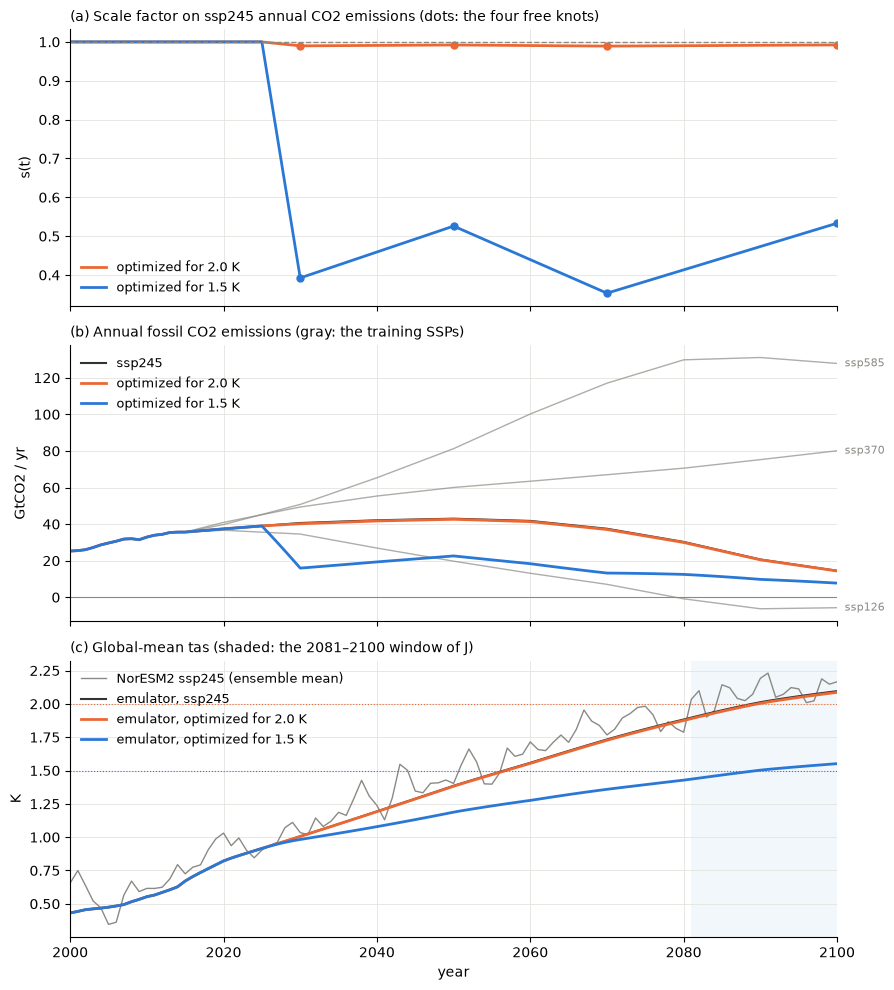

In [5]:
ssps = {exp: np.asarray(em.scenario_inputs(exp)[0]) for exp in ["ssp126", "ssp370", "ssp585"]}
fut = YEARS >= 2000
colors = {2.0: ORANGE, 1.5: BLUE}

fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
ax = axes[0]
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(r["s"])[fut], color=colors[target], label=f"optimized for {target} K")
    ax.plot(KNOTS[1:], np.asarray(r["k"]), "o", color=colors[target], ms=5)
ax.axhline(1, color=GRAY, lw=1, ls="--")
ax.set_ylabel("s(t)")
ax.set_title("(a) Scale factor on ssp245 annual CO2 emissions (dots: the four free knots)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
for exp, c in ssps.items():
    ax.plot(YEARS[fut], np.diff(c, prepend=0.0)[fut], color=GRAY, lw=1, alpha=0.7)
    ax.text(2101, np.diff(c)[-1], exp, color=GRAY, fontsize=8, va="center")
ax.plot(YEARS[fut], np.asarray(E)[fut], color="#33332f", lw=1.5, label="ssp245")
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(r["s"] * E)[fut], color=colors[target], label=f"optimized for {target} K")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_ylabel("GtCO2 / yr")
ax.set_title("(b) Annual fossil CO2 emissions (gray: the training SSPs)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[2]
ax.axvspan(2081, 2100, color=BLUE, alpha=0.06, lw=0)
ax.plot(YEARS[fut], gmt(em.load_tas("historical").values).tolist()[150:] + gmt(em.load_tas("ssp245").values).tolist(),
        color=GRAY, lw=1, label="NorESM2 ssp245 (ensemble mean)")
ax.plot(YEARS[fut], np.asarray(gmt(emulate(co2, ch4, so2, bc)))[fut], color="#33332f", lw=1.5,
        label="emulator, ssp245")
for target, r in runs.items():
    ax.plot(YEARS[fut], np.asarray(gmt(emulate(r["co2"], ch4, so2, bc)))[fut], color=colors[target],
            label=f"emulator, optimized for {target} K")
    ax.axhline(target, color=colors[target], lw=0.8, ls=":")
ax.set_xlim(2000, 2100)
ax.set_xlabel("year")
ax.set_ylabel("K")
ax.set_title("(c) Global-mean tas (shaded: the 2081–2100 window of J)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task4_pathway.png", dpi=150, bbox_inches="tight")

**The shape of the pathway.** The cheapest pathway does not cut the latest years hardest, and it does not cut the
largest emissions hardest. From Week 7 Task 2, a tonne emitted at any time before about 2080 has the same effect on $J$,
and $D$ charges the square of the tonnes removed in each year. The best answer is therefore to remove about the same
number of tonnes every year from 2026 to about 2080. In terms of $s$ that means $s - 1 \propto 1/E$: the factor stays
closest to 1 near 2050, where ssp245 emissions are largest, and the 2030 and 2070 knots move most. Emissions after
2080 count only partly in $J$, so the 2100 knot moves less than a cut of equal tonnes would need.

### How the pathway relates to the TCRE

The emulator's TCRE is 0.386 K per 1000 GtCO2 (Week 7 Task 2), and $J$ responds only to cumulative CO2. So the
reduction in $J$ should equal the TCRE times the reduction in cumulative CO2, averaged over the window with the 1-year
lag. Below, the cut in cumulative CO2 is compared with the cut that the TCRE predicts.

In [6]:
for target, r in runs.items():
    dJ = float(J(r["k"])) - J0
    cut = np.asarray(r["co2"] - co2)
    print(f"T* = {target} K: dJ = {dJ:+.3f} K. Cut in cumulative CO2: by 2080 {cut[2080 - 1850]:+.0f}, "
          f"by 2100 {cut[-1]:+.0f}, mean over 2081-2100 {cut[-20:].mean():+.0f} GtCO2. "
          f"dJ / TCRE = {1000 * dJ / TCRE:+.0f} GtCO2")
    print(f"           remaining budget from 2026: {float(r['co2'][-1] - co2[2025 - 1850]):.0f} GtCO2 to 2100 "
          f"(ssp245: {float(co2[-1] - co2[2025 - 1850]):.0f})")

T* = 2.0 K: dJ = -0.009 K. Cut in cumulative CO2: by 2080 -20, by 2100 -24, mean over 2081-2100 -22 GtCO2. dJ / TCRE = -22 GtCO2
           remaining budget from 2026: 2589 GtCO2 to 2100 (ssp245: 2613)
T* = 1.5 K: dJ = -0.508 K. Cut in cumulative CO2: by 2080 -1189, by 2100 -1414, mean over 2081-2100 -1325 GtCO2. dJ / TCRE = -1317 GtCO2
           remaining budget from 2026: 1199 GtCO2 to 2100 (ssp245: 2613)


The two numbers agree within a few percent. The small difference comes from the emissions inside the window: they
count in $J$ only for the years after they occur, so the mean cut over 2081–2100 is a little larger than the cut that
the TCRE gives. **The optimizer found the TCRE again.** In this emulator, a warming target is a budget of cumulative
CO2, and the only choice left to the optimizer is how to spread the cut over the years, which $D$ decides.

That is a property of the emulator, not a discovery. A real carbon budget has more terms: the zero-emissions
commitment, the CH4 and aerosol changes that come with a CO2 cut in real scenarios, and the curvature of the TCRE. The
emulator has none of these (see the Week 7 Task 2 and Task 3 notes).

### Is the optimized scenario inside the training range?

There are three ways to tell, from the simplest to the most direct:

1. **Each input, year by year.** Is the annual and the cumulative CO2 between the lowest and the highest training SSP
   in every year?
2. **The rate of change.** Is the fastest year-on-year fall in emissions faster than any training scenario has?
3. **The combination of inputs, as the emulator sees them.** The emulator uses four lagged, scaled features
   `[CO2, CH4, SO2 EOF1, BC EOF1]`. For each year we find the distance to the nearest year of any training experiment
   in that feature space. ssp245 is not in the training set, so its own distance is the reference: it is a scenario
   where we know the emulator works (Task 1 score).

In [7]:
feat = lambda c, m, s, b: np.asarray(em.features(params["const"], c, m, s, b))
train = np.concatenate([feat(*em.scenario_inputs(e))[-em.n_years(e):] for e in em.TRAIN])
train_exp = np.concatenate([[e] * em.n_years(e) for e in em.TRAIN])
ssp_years = YEARS >= 2015
yrs = YEARS[ssp_years]


def nearest(f):
    # distance (in scaled-feature units) from each row of f to the nearest training row, and that row's experiment
    d = np.sqrt(((f[:, None, :] - train[None, :, :]) ** 2).sum(-1))
    return d.min(1), train_exp[d.argmin(1)]


def fall(e):
    # fastest year-on-year fall in annual emissions from 2015, and its year
    step = -np.diff(e[ssp_years])
    return step.max(), yrs[1:][step.argmax()]


TRAIN_SSPS = ["ssp126", "ssp370", "ssp585"]
cum = np.stack([np.asarray(em.scenario_inputs(e)[0])[ssp_years] for e in TRAIN_SSPS])
ann = np.diff(np.stack([np.asarray(em.scenario_inputs(e)[0]) for e in TRAIN_SSPS]), prepend=0.0)[:, ssp_years]
print("fastest fall in annual CO2 (GtCO2/yr per year): "
      + ", ".join(f"{e} {fall(np.diff(np.asarray(em.scenario_inputs(e)[0]), prepend=0.0))[0]:.2f}" for e in TRAIN_SSPS)
      + f", ssp245 {fall(np.asarray(E))[0]:.2f} (in {fall(np.asarray(E))[1]})")


def years_out(x, low, high):
    # "below 2028-2078" style summary of the years where x leaves [low, high]
    parts = [f"{side} in {len(y)} years ({y.min()}-{y.max()})" for side, y in
             [("below", yrs[x < low - 1e-6]), ("above", yrs[x > high + 1e-6])] if len(y)]
    return ", ".join(parts) or "inside in every year"


dist = {"ssp245": nearest(feat(co2, ch4, so2, bc)[ssp_years])}
for target, r in runs.items():
    c, e = np.asarray(r["co2"])[ssp_years], np.asarray(r["s"] * E)[ssp_years]
    dist[f"optimized for {target} K"] = nearest(feat(r["co2"], ch4, so2, bc)[ssp_years])
    print(f"\nT* = {target} K, compared with the training SSPs:")
    print(f"  annual CO2:     {years_out(e, ann.min(0), ann.max(0))}")
    print(f"  cumulative CO2: {years_out(c, cum.min(0), cum.max(0))}; "
          f"2100 total {c[-1]:.0f} GtCO2 (ssp126 {cum[0, -1]:.0f})")
    print(f"  fastest fall {fall(np.asarray(r['s'] * E))[0]:.2f} GtCO2/yr per year (in "
          f"{fall(np.asarray(r['s'] * E))[1]}); lowest annual CO2 after 2025 {e[yrs > 2025].min():.1f} GtCO2/yr")
print()
for name, (d, exp) in dist.items():
    print(f"nearest-training distance, {name}: median {np.median(d):.2f}, max {d.max():.2f} "
          f"(in {yrs[d.argmax()]}); nearest experiment in 2100: {exp[-1]}")

fastest fall in annual CO2 (GtCO2/yr per year): ssp126 0.79, ssp370 -0.34, ssp585 0.33, ssp245 0.96 (in 2082)

T* = 2.0 K, compared with the training SSPs:
  annual CO2:     inside in every year
  cumulative CO2: inside in every year; 2100 total 4501 GtCO2 (ssp126 2793)
  fastest fall 0.95 GtCO2/yr per year (in 2090); lowest annual CO2 after 2025 14.4 GtCO2/yr

T* = 1.5 K, compared with the training SSPs:
  annual CO2:     below in 22 years (2026-2047)
  cumulative CO2: below in 51 years (2028-2078); 2100 total 3111 GtCO2 (ssp126 2793)
  fastest fall 4.77 GtCO2/yr per year (in 2030); lowest annual CO2 after 2025 7.7 GtCO2/yr

nearest-training distance, ssp245: median 0.65, max 1.03 (in 2100); nearest experiment in 2100: ssp126
nearest-training distance, optimized for 2.0 K: median 0.64, max 1.02 (in 2100); nearest experiment in 2100: ssp126
nearest-training distance, optimized for 1.5 K: median 0.34, max 0.53 (in 2100); nearest experiment in 2100: ssp126


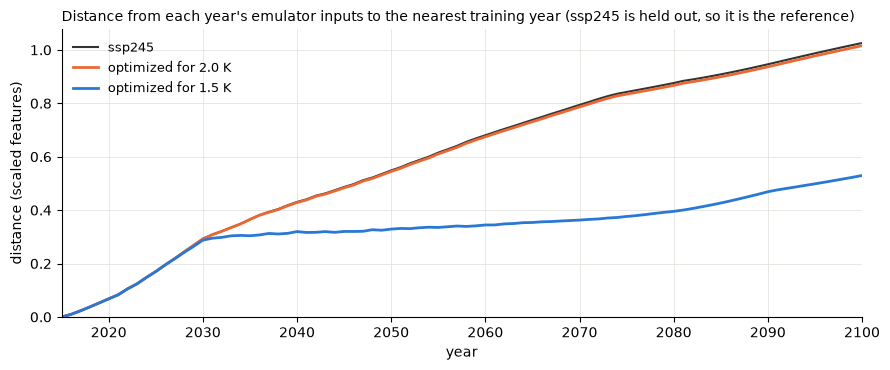

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for (name, (d, _)), color in zip(dist.items(), ["#33332f", ORANGE, BLUE]):
    ax.plot(YEARS[ssp_years], d, color=color, lw=1.5 if name == "ssp245" else 2, label=name)
ax.set_xlim(2015, 2100)
ax.set_ylim(0, None)
ax.set_xlabel("year")
ax.set_ylabel("distance (scaled features)")
ax.set_title("Distance from each year's emulator inputs to the nearest training year "
             "(ssp245 is held out, so it is the reference)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task4_extrapolation.png", dpi=150, bbox_inches="tight")

## Notes (Task 4, and Question 3)

- **Setup.** $s(t)$ is linear between knots at 2030, 2050, 2070 and 2100, with $s = 1$ up to 2025. "As little change
  as possible" is the sum of squared changes in annual emissions after 2025, relative to ssp245's own ($D$). The penalty
  is $10^5 \cdot \mathrm{relu}(J - T^*)^2$. Optax L-BFGS gives the exact (Lagrange) answer to 3 decimals for both targets.
- **2 K.** ssp245 is already at 2.009 K in this emulator, so the answer is $s \approx 0.99$: a cut of about 24 GtCO2 by
  2100, less than one year of present emissions. It is inside the training range in every year.
- **1.5 K.** The knots are 0.39, 0.53, 0.35 and 0.53. Annual CO2 falls from 39 GtCO2/yr in 2025 to 16 in 2030, stays at
  13–23 until 2070, and is 7.7 in 2100. CO2 emitted from 2026 to 2100 is 1199 GtCO2 (ssp245: 2613).
- **TCRE.** The cut in $J$ divided by the TCRE (0.386) is 1317 GtCO2, and the mean cut in cumulative CO2 over the window
  is 1325 GtCO2. In this emulator a warming target is a cumulative-CO2 budget, so the optimizer only decides how to
  spread the cut. $D$ makes it remove about the same tonnes every year until about 2080, so $s$ stays nearest to 1
  near 2050, where emissions are largest.
- **Optimizer.** Adam does not find the answer. The penalty makes a steep wall, and $D$ is almost flat along it. With a
  constant step Adam misses the target (1.473 K). With a decaying step it reaches 1.500 K but keeps four almost equal
  knots ($D$ 0.3011 against 0.2991). L-BFGS uses curvature and finds the minimum in fewer than 100 steps.
- **Inside the training range?** It depends on the test:
  - Each input against the training SSPs: no. Annual CO2 is below ssp126 in 2026–2047, and cumulative CO2 is below it
    in 2028–2078. The 2025–2030 cut is 4.8 GtCO2/yr per year, 6 times the fastest fall in any training SSP (ssp126, 0.79).
  - The emulator's own features (lagged CO2, CH4, SO2 EOF1, BC EOF1): yes. Every year is nearer to a training year
    (median distance 0.34, nearest experiment ssp126) than ssp245 is (0.65). So the emulator interpolates here.
  - The two tests disagree because the features cannot see the rate of a cut. With a 1-year lag on cumulative CO2,
    the emulator gives the same answer for a fast and a slow cut to the same total. A feature-space test is blind to
    anything that the emulator does not use. So it can show that the emulator is not outside its own data, but it
    cannot show that NorESM2 would agree.
- **Would we trust it for policy? No.** The largest problem is the CO2 coefficient. The emulator's TCRE (0.386) is
  1.37 times NorESM2's CO2-only TCRE from 1pctCO2 (0.28, Week 7), because the coefficient also takes the warming of N2O
  and halocarbons, which rise with CO2 in the SSPs. The optimizer cuts only CO2, so those gases stay as in ssp245.
  With 0.28 the same cut gives 0.37 K, not 0.51 K, so the 1.5 K pathway would give about 1.64 K. The emulator also
  has no zero-emissions commitment and no slow climate response (1-year lag), and the 4.8 GtCO2/yr-per-year cut is
  far outside anything NorESM2 was run with.
- **What would make us trust it more:** run the optimized pathway in a model with a physical carbon cycle (FaIR, or
  NorESM2 itself); give the emulator separate terms for CO2 and the other greenhouse gases, and a slow response (a
  FaIR-like core); report a range from several emulators or seeds (Task 6); and the Task 5 stress tests.

## Task 5: stress tests

We run three scenarios that the emulator never saw. Each runs from 1850 and follows ssp245 until the change:

1. **All emissions stop in 2030.** Annual CO2, CH4, SO2 and BC are zero from 2030 on, so cumulative CO2 stays at its
   2029 value.
2. **Emissions fixed at 2015.** Annual CO2, CH4 and the SO2 and BC maps keep their 2015 values until 2100.
3. **SO2 and BC removed in 2030.** As ssp245, but the SO2 and BC maps are zero from 2030 on.

**What we expect from physics (written before running).**

| scenario | sign | size | timescale |
|---|---|---|---|
| all stop in 2030 | aerosols leaving: warming. CH4 falling: cooling. CO2: about zero (the zero-emissions commitment, AR6 likely range −0.3 to +0.3 K) | aerosols a few tenths of a K up; CH4 about 0.5 K down in total | aerosols leave the air in days to weeks, so their warming comes within a few years. CH4 decays with a ~12-year perturbation lifetime, so its cooling takes decades. The net result should be flat or a small bump for about a decade, then a slow decline |
| fixed at 2015 | warming continues | CO2 concentration keeps rising, so about TCRE × annual emissions per year | steady and almost linear |
| SO2 and BC removed in 2030 | warming (removing SO2 warms; removing BC cools a little) | a few tenths of a K. In NorESM2 hist-aer, aerosols cool by −0.75 K over 1995–2014, an upper bound | mostly within 5–10 years, mostly in the Northern Hemisphere |

The ClimateBench data has two NorESM2 runs that the emulator was **not** trained on. They let us check size and
timescale against NorESM2 itself, not just against our expectations:

- **abrupt-4xCO2**, a step change, tests the timescale.
- **ssp370-lowNTCF minus ssp370** is the closest real case to scenario 3. SO2 and BC fall to about 45% of ssp370 by 2054.
  CO2 and CH4 are the same in the ClimateBench inputs. There are 3 members, and the run ends in 2054.

In [9]:
# Task 5: build the scenarios. Every input runs 1850-2100 and follows ssp245 until the change.
SPECIES = ["CO2", "CH4", "SO2", "BC"]
FROM_2030 = jnp.asarray(YEARS >= 2030)
AFTER_2015 = jnp.asarray(YEARS > 2015)
I2015 = 2015 - 1850


def set_years(mask, x, value):
    # x with `value` in the masked years; works for (year,) series and (year, lat, lon) maps
    return jnp.where(mask.reshape((-1,) + (1,) * (x.ndim - 1)), value, x)


ssp245 = (co2, ch4, so2, bc)
annual = (E, ch4, so2, bc)                    # CO2 as annual emissions; CH4, SO2 and BC are already annual
from_annual = lambda a: (jnp.cumsum(a[0]), *a[1:])
scenarios = {
    "ssp245": ssp245,
    "all emissions stop in 2030": from_annual([set_years(FROM_2030, x, 0.0) for x in annual]),
    "emissions fixed at 2015": from_annual([set_years(AFTER_2015, x, x[I2015]) for x in annual]),
    "SO2 and BC removed in 2030": (co2, ch4, set_years(FROM_2030, so2, 0.0), set_years(FROM_2030, bc, 0.0)),
}
T = {name: np.asarray(gmt(emulate(*x))) for name, x in scenarios.items()}


def species_effects(scenario, reference, emulate=emulate):
    # change from `reference` when only one input at a time is taken from `scenario`
    base = np.asarray(gmt(emulate(*reference)))
    return {s: np.asarray(gmt(emulate(*[scenario[j] if j == i else reference[j] for j in range(4)]))) - base
            for i, s in enumerate(SPECIES)}


stop_parts = species_effects(scenarios["all emissions stop in 2030"], ssp245)
# the emulator is linear in its inputs, so the four effects add up exactly to the total change
assert np.allclose(sum(stop_parts.values()), T["all emissions stop in 2030"] - T["ssp245"], atol=1e-10)

at = lambda x, *ys: "  ".join(f"{y}: {x[y - 1850]:+.2f}" for y in ys)
print("global-mean tas (K above pre-industrial):")
for name, t in T.items():
    print(f"  {name:27s} {at(t, 2029, 2030, 2031, 2035, 2050, 2100)}")
print("\nall emissions stop in 2030, change from ssp245 by species (K):")
for s, d in stop_parts.items():
    print(f"  {s:4s} {at(d, 2029, 2030, 2031, 2040, 2100)}")

fixed, late = T["emissions fixed at 2015"], YEARS >= 2030
trend = 10 * np.polyfit(YEARS[late], fixed[late], 1)[0]
print(f"\nemissions fixed at 2015: trend 2030-2100 {trend:.3f} K/decade, residual from a straight line "
      f"{np.std(fixed[late] - np.polyval(np.polyfit(YEARS[late], fixed[late], 1), YEARS[late])):.4f} K. "
      f"TCRE x 2015 CO2 emissions ({float(E[I2015]):.1f} GtCO2/yr) = {10 * TCRE * float(E[I2015]) / 1000:.3f} K/decade")

global-mean tas (K above pre-industrial):
  ssp245                      2029: +0.99  2030: +1.01  2031: +1.02  2035: +1.10  2050: +1.38  2100: +2.10
  all emissions stop in 2030  2029: +0.99  2030: +0.91  2031: +0.89  2035: +0.87  2050: +0.87  2100: +0.87
  emissions fixed at 2015     2029: +0.88  2030: +0.89  2031: +0.91  2035: +0.96  2050: +1.17  2100: +1.86
  SO2 and BC removed in 2030  2029: +0.99  2030: +1.26  2031: +1.37  2035: +1.47  2050: +1.67  2100: +2.20

all emissions stop in 2030, change from ssp245 by species (K):
  CO2  2029: +0.00  2030: -0.01  2031: -0.02  2040: -0.17  2100: -0.94
  CH4  2029: +0.00  2030: -0.33  2031: -0.45  2040: -0.51  2100: -0.38
  SO2  2029: +0.00  2030: +0.15  2031: +0.20  2040: +0.20  2100: +0.07
  BC   2029: +0.00  2030: +0.11  2031: +0.14  2040: +0.15  2100: +0.03

emissions fixed at 2015: trend 2030-2100 0.137 K/decade, residual from a straight line 0.0000 K. TCRE x 2015 CO2 emissions (35.6 GtCO2/yr) = 0.138 K/decade


In [10]:
# Two NorESM2 runs the emulator was not trained on.
# abrupt-4xCO2 (timescale): ClimateBench gives a constant CO2 input and no CH4 or aerosols. We add one
# pre-industrial year of zeros before the step so the lag starts from equilibrium. The output file skips years after
# year 120 and is erratic there, so we use years 1-100 only.
tas4x = em.load_tas("abrupt-4xCO2")
assert (tas4x.time.values[:100] == np.arange(1, 101)).all()
c4x = jnp.asarray(em.scenario_inputs("abrupt-4xCO2")[0][:100])
zeros4x = jnp.zeros((101, *so2.shape[1:]))
abrupt = {"NorESM2": np.asarray(gmt(tas4x.values[:100])),
          "emulator": np.asarray(gmt(emulate(jnp.concatenate([jnp.zeros(1), c4x]), jnp.zeros(101),
                                             zeros4x, zeros4x)))[1:]}
print("abrupt-4xCO2, global-mean tas (K) in year:")
for name, t in abrupt.items():
    print(f"  {name:9s}" + "".join(f"{y:>5d}: {t[y - 1]:.2f}" for y in [1, 2, 5, 10, 20, 50, 100]))
print(f"  NorESM2 mean of years 81-100 {abrupt['NorESM2'][-20:].mean():.2f} K; emulator reaches "
      f"{abrupt['emulator'][0] / abrupt['emulator'][-1]:.0%} of its final value in year 1, NorESM2 "
      f"{abrupt['NorESM2'][0] / abrupt['NorESM2'][-20:].mean():.0%} of its years 81-100 mean")

# ssp370-lowNTCF minus ssp370 (aerosol cut): NorESM2 outputs end in 2054
ref_x, low_x = em.scenario_inputs("ssp370"), em.scenario_inputs("ssp370-lowNTCF")
low_tas = em.load_tas("ssp370-lowNTCF")
n_low = low_tas.sizes["time"]
LOW_YEARS = np.arange(2015, 2015 + n_low)
ratio = lambda i: (np.asarray(low_x[i]).reshape(len(YEARS), -1).sum(1)
                   / np.asarray(ref_x[i]).reshape(len(YEARS), -1).sum(1))[YEARS == LOW_YEARS[-1]][0]
print(f"\nssp370-lowNTCF / ssp370 inputs in {LOW_YEARS[-1]}: " + ", ".join(f"{s} {ratio(i):.2f}"
                                                                   for i, s in enumerate(SPECIES)))
low_parts = {s: d[-86:][:n_low] for s, d in species_effects(low_x, ref_x).items()}
low = {"NorESM2": np.asarray(gmt(low_tas.values) - gmt(em.load_tas("ssp370").values[:n_low])),
       "emulator": sum(low_parts.values())}
last20 = slice(-20, None)
print(f"lowNTCF - ssp370, mean {LOW_YEARS[-20]}-{LOW_YEARS[-1]}: NorESM2 {low['NorESM2'][last20].mean():+.3f} K, "
      f"emulator {low['emulator'][last20].mean():+.3f} K (SO2 {low_parts['SO2'][last20].mean():+.3f}, "
      f"BC {low_parts['BC'][last20].mean():+.3f})")
yr_sd = np.std(low["NorESM2"][last20] - np.polyval(np.polyfit(LOW_YEARS[last20], low["NorESM2"][last20], 1),
                                                  LOW_YEARS[last20]))
print(f"  NorESM2 year-to-year SD of the difference {yr_sd:.3f} K, so the 20-year mean has SE about "
      f"{yr_sd / np.sqrt(20):.3f} K")

# where: the pattern of the 20-year-mean difference
lat = em.load_tas("historical").lat.values
wn = np.asarray(w)
maps = {"NorESM2": (low_tas.values - em.load_tas("ssp370").values[:n_low])[last20].mean(0),
        "emulator": np.asarray(emulate(*low_x) - emulate(*ref_x))[-86:][:n_low][last20].mean(0)}
anom = {k: m - (m * wn).sum() for k, m in maps.items()}
corr = (anom["NorESM2"] * anom["emulator"] * wn).sum() / np.sqrt(
    (anom["NorESM2"] ** 2 * wn).sum() * (anom["emulator"] ** 2 * wn).sum())
hemi = lambda m, nh: (m * wn)[(lat > 0) == nh].sum() / wn[(lat > 0) == nh].sum()
for k, m in maps.items():
    print(f"  {k:9s} NH {hemi(m, True):+.2f} K, SH {hemi(m, False):+.2f} K, NH/SH {hemi(m, True) / hemi(m, False):.1f}")
print(f"  area-weighted pattern correlation {corr:.2f}")

# size of the aerosol effect, and why BC comes out with the wrong sign
hist_aer = em.scenario_inputs("hist-aer")
print(f"\nhist-aer (a training run), 1995-2014 mean: NorESM2 "
      f"{float(gmt(em.load_tas('hist-aer').values)[-20:].mean()):+.2f} K, "
      f"emulator {float(gmt(emulate(*hist_aer))[-20:].mean()):+.2f} K")
print(f"core coefficients per scaled unit: SO2 {float(params['core'][3]):+.3f}, BC {float(params['core'][4]):+.3f}; "
      f"correlation of the SO2 and BC features over the training years {np.corrcoef(train[:, 2], train[:, 3])[0, 1]:.3f}")

abrupt-4xCO2, global-mean tas (K) in year:
  NorESM2      1: 1.20    2: 1.91    5: 2.97   10: 3.12   20: 3.68   50: 3.24  100: 4.04
  emulator     1: 1.14    2: 1.53    5: 1.75   10: 1.76   20: 1.76   50: 1.76  100: 1.76
  NorESM2 mean of years 81-100 3.77 K; emulator reaches 65% of its final value in year 1, NorESM2 32% of its years 81-100 mean

ssp370-lowNTCF / ssp370 inputs in 2054: CO2 1.00, CH4 1.00, SO2 0.44, BC 0.47


lowNTCF - ssp370, mean 2035-2054: NorESM2 +0.189 K, emulator +0.238 K (SO2 +0.123, BC +0.115)
  NorESM2 year-to-year SD of the difference 0.129 K, so the 20-year mean has SE about 0.029 K
  NorESM2   NH +0.28 K, SH +0.10 K, NH/SH 2.8
  emulator  NH +0.32 K, SH +0.16 K, NH/SH 2.0
  area-weighted pattern correlation 0.58

hist-aer (a training run), 1995-2014 mean: NorESM2 -0.75 K, emulator -0.43 K
core coefficients per scaled unit: SO2 -0.143, BC -0.077; correlation of the SO2 and BC features over the training years 0.647


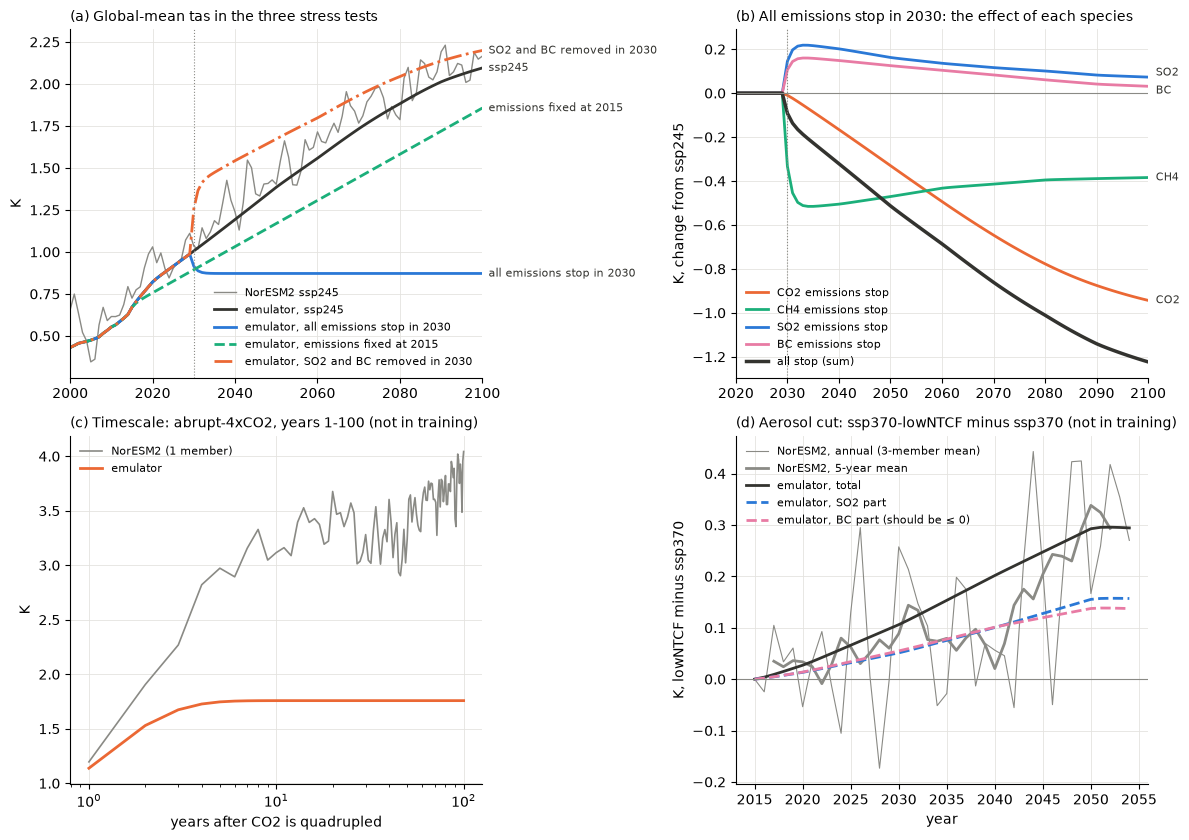

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
fut = YEARS >= 2000

ax = axes[0, 0]
noresm = np.concatenate([gmt(em.load_tas("historical").values), gmt(em.load_tas("ssp245").values)])
ax.plot(YEARS[fut], noresm[fut], color=GRAY, lw=1, label="NorESM2 ssp245")
styles = {"ssp245": ("#33332f", "-"), "all emissions stop in 2030": (BLUE, "-"),
          "emissions fixed at 2015": (AQUA, "--"), "SO2 and BC removed in 2030": (ORANGE, "-.")}
for name, t in T.items():
    color, ls = styles[name]
    ax.plot(YEARS[fut], t[fut], color=color, ls=ls, label=f"emulator, {name}")
    ax.text(2101.5, t[-1], name, color="#33332f", fontsize=8, va="center")
ax.axvline(2030, color=GRAY, lw=0.8, ls=":")
ax.set_xlim(2000, 2100)
ax.set_ylabel("K")
ax.set_title("(a) Global-mean tas in the three stress tests", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[0, 1]
colors = {"CO2": ORANGE, "CH4": AQUA, "SO2": BLUE, "BC": MAGENTA}
late = YEARS >= 2020
for s, d in stop_parts.items():
    ax.plot(YEARS[late], d[late], color=colors[s], label=f"{s} emissions stop")
    ax.text(2101.5, d[-1] + {"SO2": 0.02, "BC": -0.02}.get(s, 0), s, color="#33332f", fontsize=8, va="center")
ax.plot(YEARS[late], sum(stop_parts.values())[late], color="#33332f", lw=2.5, label="all stop (sum)")
ax.axhline(0, color=GRAY, lw=0.8)
ax.axvline(2030, color=GRAY, lw=0.8, ls=":")
ax.set_xlim(2020, 2100)
ax.set_ylabel("K, change from ssp245")
ax.set_title("(b) All emissions stop in 2030: the effect of each species", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower left")

ax = axes[1, 0]
yr = np.arange(1, 101)
ax.plot(yr, abrupt["NorESM2"], color=GRAY, lw=1.2, label="NorESM2 (1 member)")
ax.plot(yr, abrupt["emulator"], color=ORANGE, label="emulator")
ax.set_xscale("log")
ax.set_xlabel("years after CO2 is quadrupled")
ax.set_ylabel("K")
ax.set_title("(c) Timescale: abrupt-4xCO2, years 1-100 (not in training)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")

ax = axes[1, 1]
run5 = np.convolve(low["NorESM2"], np.ones(5) / 5, mode="valid")
ax.plot(LOW_YEARS, low["NorESM2"], color=GRAY, lw=0.8, label="NorESM2, annual (3-member mean)")
ax.plot(LOW_YEARS[2:-2], run5, color=GRAY, lw=2, label="NorESM2, 5-year mean")
ax.plot(LOW_YEARS, low["emulator"], color="#33332f", lw=2, label="emulator, total")
ax.plot(LOW_YEARS, low_parts["SO2"], color=BLUE, ls="--", label="emulator, SO2 part")
ax.plot(LOW_YEARS, low_parts["BC"], color=MAGENTA, ls="--", label="emulator, BC part (should be ≤ 0)")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlabel("year")
ax.set_ylabel("K, lowNTCF minus ssp370")
ax.set_title("(d) Aerosol cut: ssp370-lowNTCF minus ssp370 (not in training)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")

fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task5_stress.png", dpi=150, bbox_inches="tight")

### Does the response have the right sign, size and timescale?

**Emissions fixed at 2015: yes, and by construction.** Warming rises along an exact straight line at 0.137 K/decade,
which is the TCRE times the 2015 emissions (0.138). The sign and size are plausible. The line is perfectly straight
because the emulator has only a 1-year lag, so it has no slow response that could bend it.

**All emissions stop in 2030: the sign of the first decade is wrong, and so is the timescale.** The emulator *cools*
by 0.1 K within two years (0.99 K in 2029, 0.89 K in 2031), then levels off at 0.87 K and stays there. Panel (b) shows why:

- CH4: −0.45 K by 2031. The emulator takes CH4 *emissions* with a 1-year lag, so stopping them removes all of methane's
  warming at once. Real CH4 needs about a decade to decay (Week 7 Task 3 found the same 1-year cutoff in the gradient).
- SO2 +0.20 K and BC +0.14 K. The sign is right for SO2, but the BC sign is **wrong**: removing BC (a warming
  aerosol) warms in the emulator.
- CO2: once emissions stop, the CO2 effect stays flat. That agrees with a zero-emissions commitment near zero. But
  that comes from the input (cumulative emissions), not from a carbon cycle. NorESM2 was run with prescribed
  concentrations, and the emulator has no slow response that a carbon sink would need to cancel.

We expected aerosols to warm quickly and CH4 to cool slowly, giving flat or slightly rising temperatures for about a
decade. The emulator gives an immediate drop.

**SO2 and BC removed in 2030: the size is about right, for the wrong reasons.** The step is +0.35 K by 2031, almost all
within two years. In the held-out lowNTCF test (panel d), the emulator gives +0.24 K over 2035–2054 and NorESM2 gives
+0.19 K (± about 0.03 K standard error). But half of the emulator's warming (+0.12 K) comes from the BC cut, which
should cool. The SO2 effect is too weak: even on hist-aer, which it was trained on, the emulator gives −0.43 K against
NorESM2's −0.75 K. The two errors cancel because SO2 and BC are usually cut together. The SO2 and BC features
correlate +0.65 over the training years, so least squares cannot separate them, and the BC coefficient takes part of
the SO2 cooling. The pattern is also too even: NorESM2 warms the Northern Hemisphere 2.8 times as much as the
Southern, the emulator 2.0 times, and the map correlation is 0.58. Pattern scaling uses the greenhouse-gas pattern
for aerosols too.

**Timescale (panel c).** After quadrupled CO2, the emulator reaches 65% of its final warming in the first year and all
of it by year 5. NorESM2 reaches 32% of its years 81–100 mean in the first year and is still warming at
year 100. The emulator has a fast response and no slow one. It even starts at about the right value in year 1
(1.14 against 1.20 K), but it never shows the slow, ocean-driven part.

### What this means for Task 4

Task 4 changes only CO2, so the problems with aerosols and CH4 do not affect its answer directly. The CO2 behaviour
passed two of these tests: warming is linear in cumulative CO2 (fixed at 2015), and it stops rising when emissions
stop. So the *budget* in Task 4 (how many GtCO2 to cut) is as trustworthy as the TCRE, which is already 1.37 times
NorESM2's value. The *timing* is not: the emulator responds within about 3 years, so the warming curve along the
optimized pathway, and any target set before 2081, would be too responsive to recent emissions.

The tests also show where the optimizer would exploit the emulator. If Task 4 were allowed to change aerosols (Task 6,
"Aerosols versus CO₂"), the emulator would reward *more* BC (it cools), and an SO2 cut would cause about 40% less
warming than it does in NorESM2. Either result is an artifact.

### Notes (Task 5): what looks wrong, and possible Phase II projects

- **BC has the wrong sign** (coefficient −0.077 per scaled unit, BC removal warms by 0.14–0.15 K). Cause: SO2 and BC
  are collinear in the training data (r = 0.65). Fix: constrain the sign, or fit SO2 and BC together with a fixed
  ratio taken from known forcing.
- **SO2 is too weak**: −0.43 K against −0.75 K on hist-aer, even though hist-aer is in the training set.
- **CH4 acts instantly.** Fix: put CH4 emissions through a ~12-year decay box, to work like a concentration, before
  the linear model.
- **No slow response.** abrupt-4xCO2: the emulator levels off at 1.76 K by year 5, while NorESM2 rises from 3.1 K
  (year 10) to 3.8 K (years 81–100). Fix: a two-timescale impulse response (FaIR-like), fitted with abrupt-4xCO2 and
  1pctCO2.
- **Aerosol pattern = greenhouse-gas pattern.** Fix: a separate pattern for the aerosol part of T.
- **Data note:** `outputs_abrupt-4xCO2.nc` skips years after year 120 (121, 122, 125, …) and is erratic there, so we
  used only years 1–100.

## Task 6 (Precipitation): Task 3 with `pr` as the target

We repeat Week 7 Task 3 with precipitation. $J$ is the area-weighted mean `pr` over the South Asia box (5–30°N,
65–90°E) for 2081–2100 under ssp245, and one call to `jax.grad` gives its derivative with respect to CO2, CH4, SO2 and
BC. Set `TARGET = "pr90"` to use the 90th percentile of daily precipitation instead.

**The pr emulator.** The emulator predicts tas, so we give it a pr pattern and change nothing else:
$\mathrm{pr}(x, t) = a(x) + b(x)\,T(t)$, with the same global core $T$. The pattern is fit exactly as `em.fit` fits
the tas pattern (least squares in each cell on $[1, T]$, with NorESM2's global-mean tas), and `em.make_emulator` runs
it unchanged. The same fit on tas returns the Week 7 pattern (checked below).

**What to expect (written before running).** Only the pattern changes, so $J = \bar a + \bar b\,\bar T$, with bars
for means over the box and the window. Every pr gradient is then the Task 3 tas gradient times one number, the box
mean of the pr pattern over that of the tas pattern. It has the same shape in time, the same EOF1 map for SO2, and the
same 65% share of the SO2 effect from outside the box. Two things can still differ from temperature:

- **Noise.** Precipitation varies a lot from year to year compared with its forced change, so its pattern, and that
  one number, should be much less certain than for tas.
- **Physics.** The emulator lets rain follow only the global temperature, so all four inputs change rain by the same
  amount per kelvin. Physically they do not. Global-mean rain rises by 1–3 % per K of warming, but CO2's rapid
  adjustment cuts precipitation and offsets part of that (Myhre et al. 2017). Sulfate scatters light and has little
  fast response, so rain follows its cooling at the full rate. Black carbon heats the atmosphere, which suppresses
  rain even while the surface warms, and it is where models disagree most (Samset et al. 2016). Over South Asia,
  aerosols weakened the summer monsoon in the 20th century (Bollasina et al. 2011).

In [13]:
# Task 6 (Precipitation). Uses only the setup cell at the top of this notebook.
import xarray as xr
from metrics import nrmse

TARGET = "pr"                                                       # "pr" or "pr90"
REGION = {"name": "South Asia", "lat": (5, 30), "lon": (65, 90)}   # degrees N; degrees E in -180..180 (Week 7 Task 3)
inputs = (co2, ch4, so2, bc)
ref = em.load_tas("ssp245")
LAT, LON = ref.lat.values, ref.lon.values
wf = np.asarray(w).ravel()                                          # area weights, one per cell


def box_mask(lat, lon, lat_range, lon_range):
    # (lat, lon) boolean mask of a lat-lon box (Week 7 Task 3). lon_range is in -180..180 and may cross the dateline.
    lon = (np.asarray(lon) + 180) % 360 - 180
    (south, north), (west, east) = lat_range, lon_range
    in_lon = (lon >= west) & (lon <= east) if west <= east else (lon >= west) | (lon <= east)
    return ((np.asarray(lat) >= south) & (np.asarray(lat) <= north))[:, None] & in_lon[None, :]


in_box = box_mask(LAT, LON, REGION["lat"], REGION["lon"])
w_box = jnp.where(in_box, w, 0.0) / jnp.where(in_box, w, 0.0).sum()
wbf = np.asarray(w_box).ravel()


def load_members(exp, var):
    # NorESM2 output as (member, year, cell), pr in mm/day, NaN where a member is missing; a run with one member gets
    # a member axis of length 1
    da = xr.open_dataset(f"{em.DATA}/outputs_{exp}.nc")[var]
    da = da.transpose("member", ...) if "member" in da.dims else da.expand_dims("member")
    return da.values.reshape(da.sizes["member"], da.sizes["time"], -1).astype(np.float32) * TO_MM.get(var, 1.0)


def ens_mean(x):
    # ensemble mean that skips missing members, as xarray's .mean("member") in em.load_tas does
    with np.errstate(invalid="ignore"):
        m = np.nanmean(x, axis=0)
    assert np.isfinite(m).all(), "no member has data in some years"
    return m


# The files give no units for pr. CMIP6 stores it in kg m-2 s-1 (= mm/s), and a late-century global mean far below
# 1e-3 can only be that, so it is converted to mm/day.
TO_MM = {}
TO_MM[TARGET] = 86400.0 if abs(float(ens_mean(load_members("ssp585", TARGET))[-20:].mean(0) @ wf)) < 1e-3 else 1.0

# Some members have missing years (ssp370 in tas, at least). The ensemble mean skips them, as em.fit does; the
# one-member refits below use only members that are complete in both tas and the target.
data = {v: {} for v in ["tas", TARGET]}
for e in em.TRAIN:
    x = {v: load_members(e, v) for v in data}
    full = np.isfinite(x["tas"]).all(axis=(1, 2)) & np.isfinite(x[TARGET]).all(axis=(1, 2))
    assert full.any(), f"{e}: no member is complete"
    for v in data:
        data[v][e] = {"mean": ens_mean(x[v]), "members": x[v][full]}
    del x
n_own = {e: em.n_years(e) for e in em.TRAIN}
print(f"{TARGET}: stored value x {TO_MM[TARGET]:g} = mm/day; complete / all members per training experiment: "
      + ", ".join(f"{e} {len(data['tas'][e]['members'])}/{len(load_members(e, 'tas'))}" for e in em.TRAIN))


def t_slope(D, b, res):
    # t statistic of slope b of a least-squares fit on design D. Neighbouring years are not independent, so the
    # variance is inflated by (1 + r) / (1 - r), with r the lag-1 autocorrelation of the residuals.
    r = np.clip((res[1:] * res[:-1]).sum(0) / (res ** 2).sum(0), 0.0, 0.95)
    s2 = (res ** 2).sum(0) / (len(D) - 2) * (1 + r) / (1 - r)
    return b / np.sqrt(np.linalg.inv(D.T @ D)[1, 1] * s2)


def fit_pattern(var, member=None):
    # Least squares in each cell on [1, T], T = NorESM2's global-mean tas: how em.fit fits the tas pattern.
    # member=None fits the ensemble mean; an integer fits that member of every experiment (modulo its member count).
    pick = lambda d: d["mean"] if member is None else d["members"][member % len(d["members"])]
    Y = np.concatenate([pick(data[var][e]) for e in em.TRAIN]).astype(np.float64)
    T = np.concatenate([pick(data["tas"][e]) for e in em.TRAIN]).astype(np.float64) @ wf
    D = np.column_stack([np.ones(len(T)), T])
    pattern, *_ = np.linalg.lstsq(D, Y, rcond=None)
    res = Y - D @ pattern
    return {"pattern": pattern, "t_map": t_slope(D, pattern[1], res), "t_box": t_slope(D, pattern[1] @ wbf, res @ wbf)}


fit_tas, fit_pr = fit_pattern("tas"), fit_pattern(TARGET)
print(f"the same fit on tas vs the Week 7 pattern: max |difference| "
      f"{np.abs(fit_tas['pattern'] - np.asarray(params['pattern'])).max():.1e}")
emulate_pr = em.make_emulator({**params, "pattern": jnp.asarray(fit_pr["pattern"])})   # Week 7 emulator, pr pattern

truth_pr = ens_mean(load_members("ssp245", TARGET)).reshape(ref.shape)
score = nrmse(xr.DataArray(truth_pr, dims=ref.dims, coords=ref.coords),
              xr.DataArray(np.asarray(emulate_pr(*inputs))[-86:], dims=ref.dims, coords=ref.coords))
print(f"ssp245 (held out), {TARGET}: " + ", ".join(f"{k} {v:.3f}" for k, v in score.items())
      + "  (tas in Task 1: Total 0.345)")

pr: stored value x 86400 = mm/day; complete / all members per training experiment: historical 3/3, hist-GHG 3/3, hist-aer 3/3, ssp126 1/1, ssp370 1/3, ssp585 1/1
the same fit on tas vs the Week 7 pattern: max |difference| 4.9e-15
ssp245 (held out), pr: Spatial 1.916, Global 0.295, Total 3.394  (tas in Task 1: Total 0.345)


In [14]:
# Task 3 again: gradients of J for pr, with the Week 7 tas emulator alongside
def late_mean(f, weights):
    # J(co2, ch4, so2, bc): the `weights`-average of f's output over 2081-2100
    return lambda *x: (f(*x)[-20:] * weights).sum(axis=(1, 2)).mean()


def per_emission(dJ_dC):
    # sensitivity to a cumulative input -> effect of one extra unit emitted in each year (Week 7 Task 2)
    return jnp.cumsum(dJ_dC[::-1])[::-1]


WEIGHTS = {REGION["name"]: w_box, "global": w}
UNITS = {"tas": "K", TARGET: "mm/day"}
S = np.asarray(so2).reshape(len(YEARS), len(LAT), len(LON))
res3 = {}
for var, f in [("tas", emulate), (TARGET, emulate_pr)]:
    for where, wt in WEIGHTS.items():
        J6 = late_mean(f, wt)
        gC, gM, gS, gB = jax.grad(J6, argnums=(0, 1, 2, 3))(*inputs)
        gS = np.asarray(gS).reshape(S.shape)
        res3[(var, where)] = {"J": float(J6(*inputs)), "co2": 1000 * np.asarray(per_emission(gC)),
                              "ch4": np.asarray(gM), "so2_sum": gS.sum(0), "so2_contrib": (gS * S).sum(0),
                              "bc": float((np.asarray(gB) * np.asarray(bc)).sum())}

print("2081-2100 mean under ssp245: J, then the change in J from one extra unit emitted in 2030 (CO2, per 1000 GtCO2)")
print("or 2090 (CH4, per GtCH4), and from all of ssp245's SO2 and BC (J minus J without it). CH4 in GtCH4/yr (Week 7).")
print(f"{'':23s} {'J':>7s} {'CO2':>9s} {'CH4':>9s} {'SO2':>9s} {'BC':>9s}")
for where in WEIGHTS:
    for var in ["tas", TARGET]:
        a = res3[(var, where)]
        print(f"{where:11s} {var:4s} {UNITS[var]:>6s} {a['J']:7.3f} {a['co2'][2030 - 1850]:+9.4f} "
              f"{a['ch4'][2090 - 1850]:+9.4f} {a['so2_contrib'].sum():+9.4f} {a['bc']:+9.4f}")
print(f"NorESM2 {TARGET} 2081-2100 (ssp245, held out): {REGION['name']} "
      f"{float(truth_pr[-20:].mean(0).ravel() @ wbf):.3f}, global {float(truth_pr[-20:].mean(0).ravel() @ wf):.3f} mm/day")

# Shape check: is every pr gradient the tas gradient times one number?
a, b = res3[(TARGET, REGION["name"])], res3[("tas", REGION["name"])]
big = np.abs(b["ch4"]) > 1e-6 * np.abs(b["ch4"]).max()
ratios = np.concatenate([a["co2"] / b["co2"], a["ch4"][big] / b["ch4"][big]])
print(f"\n{TARGET} / tas, every year of the CO2 and CH4 curves: {ratios.min():.6g} to {ratios.max():.6g}; box mean of "
      f"the {TARGET} pattern / tas pattern: {(fit_pr['pattern'][1] @ wbf) / (np.asarray(params['pattern'][1]) @ wbf):.6g}")
print(f"correlation of the summed SO2 gradient maps, {TARGET} vs tas: "
      f"{np.corrcoef(a['so2_sum'].ravel(), b['so2_sum'].ravel())[0, 1]:+.6f}")

# Where does the SO2 effect on the region come from? (Week 7's crude source boxes, each cell counted once)
SOURCES = {f"{REGION['name']} (the target box)": (REGION["lat"], REGION["lon"]),
           "East Asia": ((20, 50), (100, 145)),
           "Southeast Asia": ((-12, 20), (90, 155)),
           "Europe": ((35, 72), (-12, 45)),
           "Middle East and Central Asia": ((12, 50), (35, 100)),
           "Russia and North Asia": ((50, 80), (45, 180)),
           "Africa": ((-40, 37), (-20, 52)),
           "North America": ((15, 75), (-170, -50)),
           "South and Central America": ((-60, 15), (-120, -30))}
contrib, taken = a["so2_contrib"], np.zeros(in_box.shape, bool)
print(f"\nSO2 effect on 2081-2100 {TARGET} over {REGION['name']} by source region:")
for name, box in list(SOURCES.items()) + [("everywhere else (sea, rest)", None)]:
    m = ~taken if box is None else box_mask(LAT, LON, *box) & ~taken
    taken |= m
    print(f"  {name:30s} {contrib[m].sum():+.4f} mm/day {contrib[m].sum() / contrib.sum():6.0%}")

2081-2100 mean under ssp245: J, then the change in J from one extra unit emitted in 2030 (CO2, per 1000 GtCO2)
or 2090 (CH4, per GtCH4), and from all of ssp245's SO2 and BC (J minus J without it). CH4 in GtCH4/yr (Week 7).
                              J       CO2       CH4       SO2        BC
South Asia  tas       K   2.014   +0.3961   +0.0703   -0.0861   -0.0439
South Asia  pr   mm/day   0.536   +0.0992   +0.0176   -0.0216   -0.0110
global      tas       K   2.009   +0.3858   +0.0685   -0.0839   -0.0428
global      pr   mm/day   0.050   +0.0115   +0.0020   -0.0025   -0.0013
NorESM2 pr 2081-2100 (ssp245, held out): South Asia 0.502, global 0.067 mm/day

pr / tas, every year of the CO2 and CH4 curves: 0.250463 to 0.250463; box mean of the pr pattern / tas pattern: 0.250463
correlation of the summed SO2 gradient maps, pr vs tas: +1.000000

SO2 effect on 2081-2100 pr over South Asia by source region:
  South Asia (the target box)    -0.0075 mm/day    35%
  East Asia                      

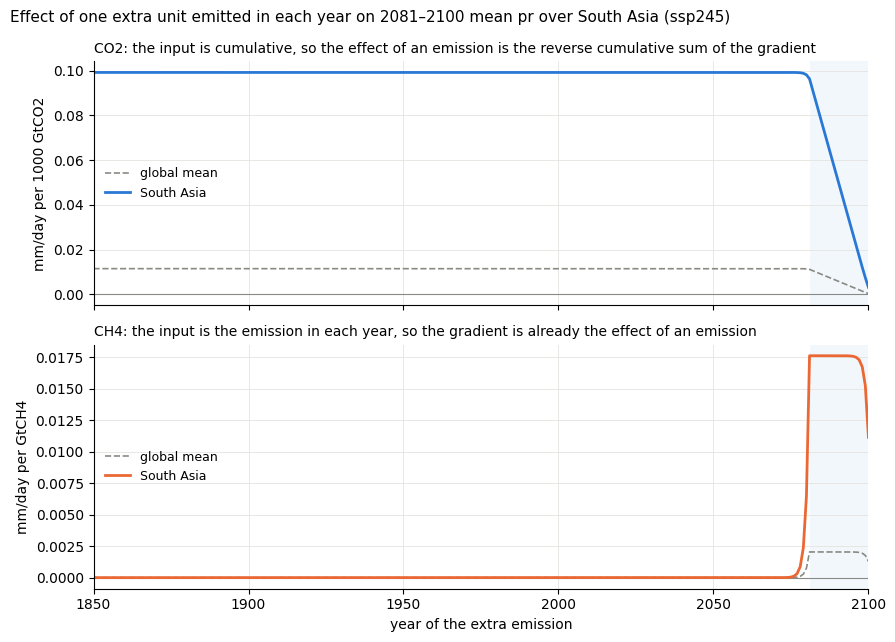

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
panels = [(axes[0], "co2", "mm/day per 1000 GtCO2", BLUE,
           "CO2: the input is cumulative, so the effect of an emission is the reverse cumulative sum of the gradient"),
          (axes[1], "ch4", "mm/day per GtCH4", ORANGE,
           "CH4: the input is the emission in each year, so the gradient is already the effect of an emission")]
for ax, key, unit, color, title in panels:
    reg, glob = res3[(TARGET, REGION["name"])][key], res3[(TARGET, "global")][key]
    ax.axvspan(2081, 2100, color=BLUE, alpha=0.06, lw=0)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.plot(YEARS, glob, color=GRAY, lw=1.2, ls="--", label="global mean")
    ax.plot(YEARS, reg, color=color, label=REGION["name"])
    ax.set_ylabel(unit)
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=9, loc="center left")
axes[1].set_xlim(1850, 2100)
axes[1].set_xlabel("year of the extra emission")
fig.suptitle(f"Effect of one extra unit emitted in each year on 2081–2100 mean {TARGET} over {REGION['name']} (ssp245)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task6_{TARGET}_co2_ch4.png", dpi=150, bbox_inches="tight")

### Noisier or less physical than for temperature?

Since every pr gradient is the tas gradient times the ratio of the two box-mean patterns, both questions are about
that one number.

**Noise.** We refit the pr pattern on one NorESM2 ensemble member at a time (members with missing years are left
out) and keep the core. The members differ
only by internal variability, so the spread across members is the noise that weather puts into the gradients. The
same refit for tas gives the reference. The t statistic of the box-mean slope gives a second measure that uses every
year, and the share of the Earth where the pattern has |t| above 2 shows how much of the map is signal.

**Physics.** hist-GHG and hist-aer are NorESM2's own answer to how much greenhouse gases and aerosols change rain per
kelvin. The emulator has to give both the same value. They are training runs, so this tests the emulator's structure,
not its skill on new data. Changes are 1995–2014 minus 1850–1879.

In [16]:
def pcorr(a, b):
    # area-weighted correlation of two maps after removing their global means
    a, b = a - a @ wf, b - b @ wf
    return (a * b) @ wf / np.sqrt(((a * a) @ wf) * ((b * b) @ wf))


def change(x):
    # 1995-2014 mean minus 1850-1879 mean, along the year axis
    return x[-20:].mean(0) - x[:30].mean(0)


# Noise: refit the pattern on one member at a time
n_mem = max(len(d["members"]) for d in data["tas"].values())
assert n_mem > 1, "the noise test needs at least two members"
noise = {}
for var, f0 in [("tas", fit_tas), (TARGET, fit_pr)]:
    fs = [fit_pattern(var, member=i) for i in range(n_mem)]
    ens, mem = f0["pattern"][1] @ wbf, np.array([f["pattern"][1] @ wbf for f in fs])
    noise[var] = {"ens": ens, "members": mem, "spread": mem.std(ddof=1) / abs(ens), "t": f0["t_box"],
                  "map_r": np.mean([pcorr(fs[i]["pattern"][1], fs[k]["pattern"][1])
                                    for i in range(n_mem) for k in range(i + 1, n_mem)]),
                  "area_t2": (np.abs(f0["t_map"]) > 2) @ wf}
print(f"Box-mean slope of the pattern over {REGION['name']} (K per K for tas, mm/day per K for {TARGET}), "
      f"and the whole map:")
print(f"{'':5s} {'ens. mean':>10s} {'members':>{10 * n_mem}s} {'spread':>7s} {'t':>7s} {'member map r':>13s} "
      f"{'|t|>2':>6s}")
for var, nz in noise.items():
    print(f"{var:5s} {nz['ens']:+10.4f} {''.join(f'{x:+10.4f}' for x in nz['members'])} {nz['spread']:7.1%} "
          f"{nz['t']:+7.1f} {nz['map_r']:13.2f} {nz['area_t2']:6.0%}")

# Physics: rain per kelvin in NorESM2's single-forcing runs, against the emulator's single value
phys, aer_maps = {}, {}
for exp in ["hist-GHG", "hist-aer", "historical"]:
    n = n_own[exp]
    emu = np.asarray(emulate_pr(*em.scenario_inputs(exp)))[-n:].reshape(n, -1)
    nor = data[TARGET][exp]["mean"]
    phys[exp] = {"dT": change(data["tas"][exp]["mean"] @ wf),
                 "nor": (change(nor @ wf), change(nor @ wbf)), "emu": (change(emu @ wf), change(emu @ wbf))}
    if exp == "hist-aer":
        aer_maps = {"NorESM2": change(nor), "emulator": change(emu)}
b_glob, b_box = fit_pr["pattern"][1] @ wf, fit_pr["pattern"][1] @ wbf
print(f"\nChange from 1850-1879 to 1995-2014; {TARGET} in mm/day, per K = per K of NorESM2's global-mean tas change")
print(f"{'':11s} {'global tas':>10s} {'global: NorESM2':>16s} {'emulator':>9s} {'per K':>7s}   "
      f"{REGION['name'] + ': NorESM2':>20s} {'emulator':>9s} {'per K':>7s}")
for exp, p in phys.items():
    print(f"{exp:11s} {p['dT']:+10.3f} {p['nor'][0]:+16.4f} {p['emu'][0]:+9.4f} {p['nor'][0] / p['dT']:+7.4f}   "
          f"{p['nor'][1]:+20.4f} {p['emu'][1]:+9.4f} {p['nor'][1] / p['dT']:+7.4f}")
print(f"emulator, every input: global {b_glob:+.4f}, {REGION['name']} {b_box:+.4f} mm/day per K")

nz, nt = noise[TARGET], noise["tas"]
g, a = phys["hist-GHG"], phys["hist-aer"]
print(f"\nSUMMARY ({TARGET}, {REGION['name']})")
print(f"Noise: refit on one member at a time, the {TARGET} gradients vary by {nz['spread']:.1%} (tas {nt['spread']:.1%}); "
      f"t of the box-mean slope {nz['t']:.1f} (tas {nt['t']:.1f}); the pattern is distinguishable from noise "
      f"(|t| > 2) over {nz['area_t2']:.0%} of the Earth (tas {nt['area_t2']:.0%}), and members' maps correlate "
      f"{nz['map_r']:.2f} (tas {nt['map_r']:.2f}).")
print(f"Physics: per K of global warming, NorESM2 changes global {TARGET} by {g['nor'][0] / g['dT']:+.4f} mm/day for "
      f"greenhouse gases and {a['nor'][0] / a['dT']:+.4f} for aerosols (ratio {(a['nor'][0] / a['dT']) / (g['nor'][0] / g['dT']):.1f}); "
      f"the emulator uses {b_glob:+.4f} for both. Over {REGION['name']}: NorESM2 {g['nor'][1] / g['dT']:+.4f} and "
      f"{a['nor'][1] / a['dT']:+.4f}, emulator {b_box:+.4f}.")
print(f"Signs over {REGION['name']}: more SO2 makes it {'drier' if res3[(TARGET, REGION['name'])]['so2_contrib'].sum() < 0 else 'wetter'} "
      f"in the emulator; aerosols made it {'drier' if a['nor'][1] < 0 else 'wetter'} in NorESM2 hist-aer "
      f"({a['nor'][1]:+.3f} mm/day, emulator {a['emu'][1]:+.3f}).")

Box-mean slope of the pattern over South Asia (K per K for tas, mm/day per K for pr), and the whole map:
       ens. mean                        members  spread       t  member map r  |t|>2
tas      +1.0268    +1.0302   +1.0304   +1.0320    0.1%  +119.8          1.00    99%
pr       +0.2572    +0.2486   +0.2446   +0.2467    0.8%   +16.7          1.00    85%

Change from 1850-1879 to 1995-2014; pr in mm/day, per K = per K of NorESM2's global-mean tas change
            global tas  global: NorESM2  emulator   per K    South Asia: NorESM2  emulator   per K
hist-GHG        +0.952          +0.0380   +0.0252 +0.0399                +0.2737   +0.2172 +0.2876
hist-aer        -0.780          -0.0712   -0.0130 +0.0912                -0.2030   -0.1124 +0.2601
historical      +0.425          -0.0159   +0.0121 -0.0374                +0.1535   +0.1048 +0.3610
emulator, every input: global +0.0298, South Asia +0.2572 mm/day per K

SUMMARY (pr, South Asia)
Noise: refit on one member at a time, the pr g

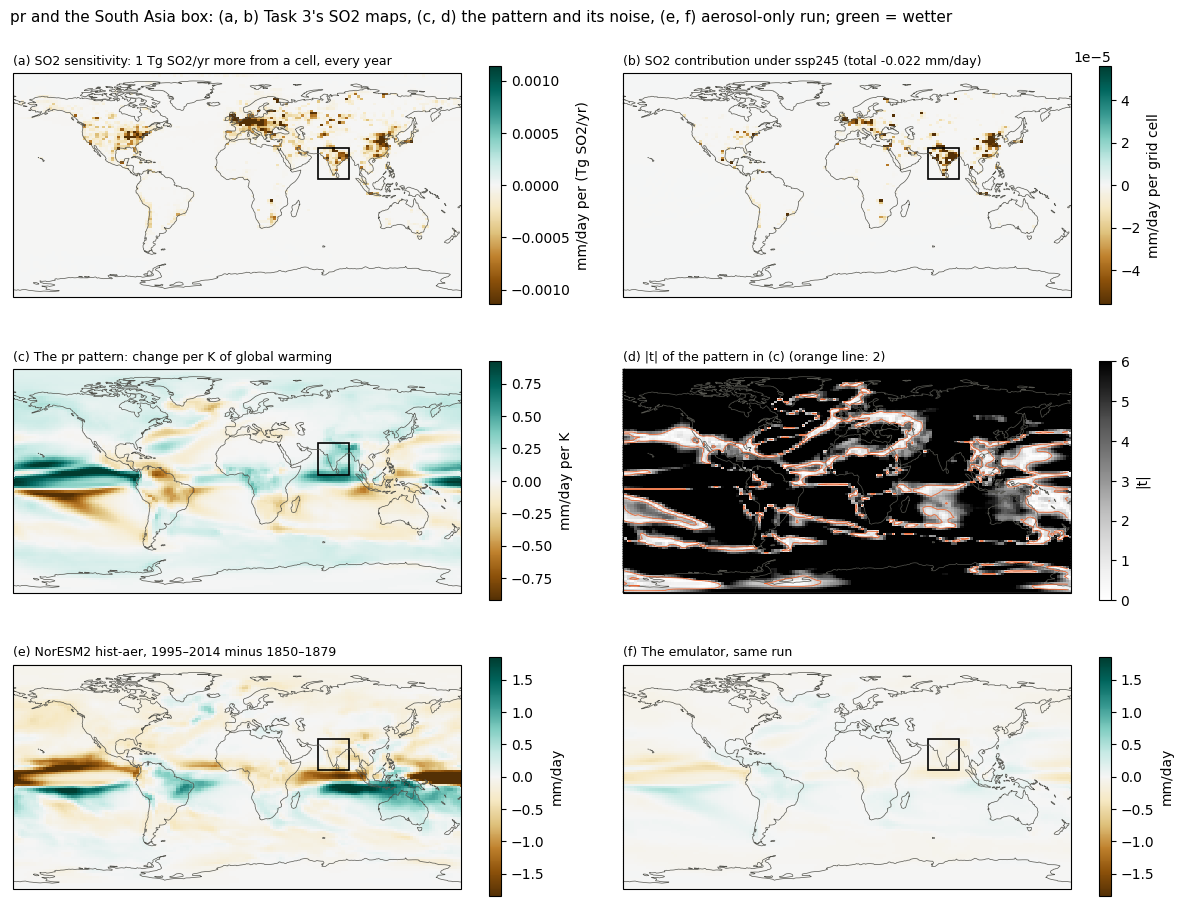

In [17]:
SEC_PER_YEAR, R_EARTH = 365.25 * 86400, 6.371e6


def cell_area(lat, n_lon):
    # area (m2) of each cell of a regular lat-lon grid with centres `lat` (Week 7 Task 3)
    mid = (lat[1:] + lat[:-1]) / 2
    edges = np.clip(np.concatenate([[2 * lat[0] - mid[0]], mid, [2 * lat[-1] - mid[-1]]]), -90, 90)
    band = np.abs(np.diff(np.sin(np.deg2rad(edges))))
    return np.repeat(R_EARTH**2 * 2 * np.pi / n_lon * band[:, None], n_lon, axis=1)


TG = cell_area(LAT, len(LON)) * SEC_PER_YEAR / 1e9      # Tg SO2/yr per unit of the input (kg m-2 s-1; Week 7)
try:
    import cartopy.crs as ccrs
    MAP = {"projection": ccrs.PlateCarree()}
except ImportError:          # plain lat-lon axes
    ccrs, MAP = None, {}
order = np.argsort((LON + 180) % 360 - 180)
lon_plot = ((LON + 180) % 360 - 180)[order]
geo = {"transform": ccrs.PlateCarree()} if ccrs else {}
grid = lambda m: np.asarray(m).reshape(len(LAT), len(LON))[:, order]
sym = lambda *ms: float(np.nanpercentile(np.abs(np.concatenate([np.ravel(m) for m in ms])), 99.5)) or 1.0
r = res3[(TARGET, REGION["name"])]
lim_aer = sym(aer_maps["NorESM2"], aer_maps["emulator"])
panels = [(r["so2_sum"] / TG, "BrBG", sym(r["so2_sum"] / TG), "mm/day per (Tg SO2/yr)",
           "(a) SO2 sensitivity: 1 Tg SO2/yr more from a cell, every year"),
          (r["so2_contrib"], "BrBG", sym(r["so2_contrib"]), "mm/day per grid cell",
           f"(b) SO2 contribution under ssp245 (total {r['so2_contrib'].sum():+.3f} mm/day)"),
          (fit_pr["pattern"][1], "BrBG", sym(fit_pr["pattern"][1]), "mm/day per K",
           f"(c) The {TARGET} pattern: change per K of global warming"),
          (np.abs(fit_pr["t_map"]), "Greys", None, "|t|", "(d) |t| of the pattern in (c) (orange line: 2)"),
          (aer_maps["NorESM2"], "BrBG", lim_aer, "mm/day", "(e) NorESM2 hist-aer, 1995–2014 minus 1850–1879"),
          (aer_maps["emulator"], "BrBG", lim_aer, "mm/day", "(f) The emulator, same run")]

fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), subplot_kw=MAP)
(s, n), (wl, el) = REGION["lat"], REGION["lon"]
for ax, (field, cmap, lim, unit, title) in zip(axes.ravel(), panels):
    if lim is None:
        pcm = ax.pcolormesh(lon_plot, LAT, grid(field), cmap=cmap, vmin=0, vmax=6, shading="nearest", **geo)
        ax.contour(lon_plot, LAT, grid(field), levels=[2], colors=ORANGE, linewidths=0.6, **geo)
    else:
        pcm = ax.pcolormesh(lon_plot, LAT, grid(field), cmap=cmap, vmin=-lim, vmax=lim, shading="nearest", **geo)
    ax.add_patch(plt.Rectangle((wl, s), el - wl, n - s, fill=False, ec="black", lw=1.2, **geo))
    if ccrs:
        ax.coastlines(lw=0.5, color="#55554f")
        ax.set_global()
    else:
        ax.set_xlim(-180, 180)
        ax.set_ylim(-90, 90)
        ax.set_aspect("equal")
        ax.grid(False)
    ax.set_title(title, loc="left", fontsize=9)
    fig.colorbar(pcm, ax=ax, shrink=0.8, label=unit)
fig.suptitle(f"{TARGET} and the South Asia box: (a, b) Task 3's SO2 maps, (c, d) the pattern and its noise, "
             f"(e, f) aerosol-only run; green = wetter", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIGS}/week8_task6_{TARGET}_maps.png", dpi=150, bbox_inches="tight")

### Answer

**Noisier: not in shape, but in size.** The shape check shows every pr gradient is the Task 3 tas gradient times one
constant (the ratio is the same in every year, and the SO2 maps correlate +1). So the pr gradients cannot be noisier in
*when* emissions matter or *where* SO2 matters: the 1-year lag and the EOF1 projection come before the target, and the
source table gives the same shares as Week 7 (65% from outside South Asia). The noise is all in that one constant,
the box mean of the pr pattern. The summary gives its spread across members, its t statistic and the share of the map
that is signal, each against tas; maps (c) and (d) show where the pr pattern stands out from the noise.

**Less physical: yes, by construction.** The emulator can only make rain follow global temperature, so CO2, CH4, SO2
and BC all change rain by the same amount per kelvin. For temperature that is a fair approximation and the design of
the emulator. For precipitation it is wrong in a known way: CO2's rapid adjustment lowers rain per kelvin, sulfate
gives about the full temperature-driven response, and black carbon can dry while it warms. The summary compares
NorESM2's own rain per kelvin for greenhouse gases and for aerosols with the emulator's single value, and maps (e) and
(f) show the aerosol-only case. The SO2 gradient over South Asia gets its sign only through global cooling, not
through the aerosol's own effect on the monsoon, and the BC gradient inherits BC's wrong sign from the tas core
(Task 5).

## Notes (Task 6)

- **Emulator.** The Week 7 emulator with a pr pattern, fit exactly as `em.fit` fits the tas pattern; the same code on
  tas reproduces the Week 7 pattern.
- **Gradients.** pr gradients = tas gradients × (box-mean pr pattern / box-mean tas pattern). Same timing (CO2 flat
  until about 2080; CH4, SO2 and BC only in the last two decades), same EOF1 map for SO2, same source shares.
- **Noise** sits in one number per region. The summary gives it against tas.
- **Physics.** One rain-per-kelvin for every input. Giving the pr part its own coefficient for each input would fix
  this in principle, but the training runs move SO2 and BC together (r = 0.65, Task 5), so the data could not pin
  those coefficients down well.